# Random Forest

Random Forest is an ensemble learning method that combines multiple decision trees to create a more robust and accurate model.

## 1. Setup and Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             roc_auc_score, roc_curve, precision_score, recall_score,
                             f1_score)
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore')

# Set random seed for reproducibility
np.random.seed(42)

# Plotting style
plt.style.use('seaborn-v0_8-darkgrid')
%matplotlib inline

## 2. What is Random Forest?

### Definition
Random Forest is an ensemble learning method that:
- **Builds multiple decision trees** on different subsets of data
- **Averages predictions** from all trees (for regression) or uses voting (for classification)
- **Reduces overfitting** by introducing randomness

### Key Concepts:

1. **Bootstrap Aggregation (Bagging)**:
   - Creates multiple subsets of the training data by sampling with replacement
   - Each tree is trained on a different bootstrap sample

2. **Random Feature Selection**:
   - Each node in a tree considers only a random subset of features
   - Reduces correlation between trees

3. **Ensemble Voting**:
   - For classification: majority voting
   - For regression: average of predictions

### Intuition
"The wisdom of the crowd" - multiple trees working together make better decisions than a single tree.

## 3. Load and Explore Diabetes Dataset

In [2]:
# Load the dataset
df = pd.read_csv('diabetes_dataset.csv')

print("=== Diabetes Dataset Overview ===")
print(f"Dataset shape: {df.shape}")
print(f"Features: {df.columns.tolist()}")
print()

# Display first few rows
print("First 5 rows of the dataset:")
display(df.head())
print()

# Dataset information
print("Dataset Info:")
print(df.info())
print()

# Statistical summary
print("Statistical Summary:")
display(df.describe())

=== Diabetes Dataset Overview ===
Dataset shape: (768, 9)
Features: ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']

First 5 rows of the dataset:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1



Dataset Info:
<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB
None

Statistical Summary:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


Missing Values:
No missing values found!

Features with Zero Values (possible missing values):
Glucose: 5 zero values (0.7%)
BloodPressure: 35 zero values (4.6%)
SkinThickness: 227 zero values (29.6%)
Insulin: 374 zero values (48.7%)
BMI: 11 zero values (1.4%)

Target Variable Distribution:
Class 0 (No Diabetes): 500 samples (65.1%)
Class 1 (Diabetes): 268 samples (34.9%)


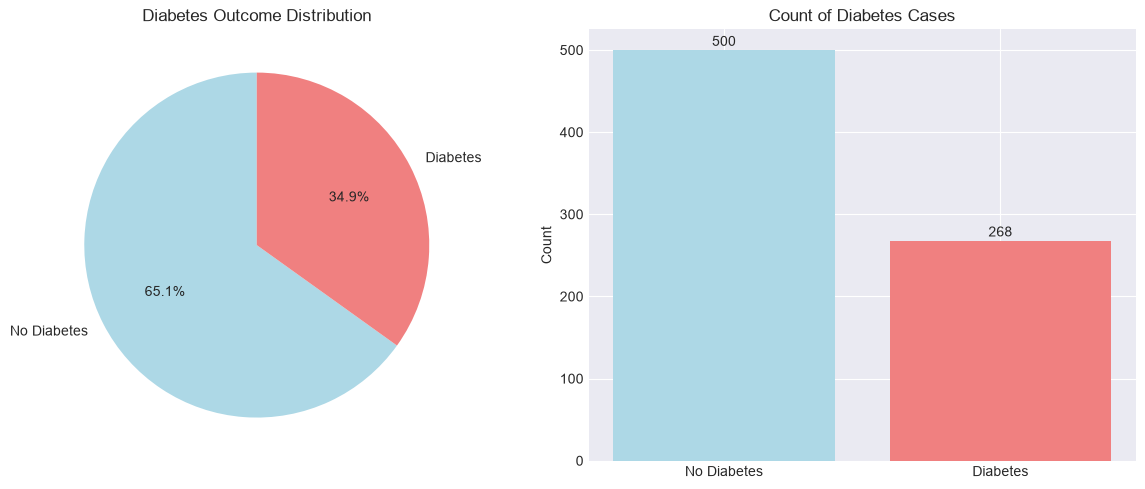

In [3]:
# Check for missing values
print("Missing Values:")
missing = df.isnull().sum()
print(missing[missing > 0] if any(missing > 0) else "No missing values found!")
print()

# Check for zero values in features (possible missing data indicator)
print("Features with Zero Values (possible missing values):")
features_with_zero = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
for feature in features_with_zero:
    zero_count = (df[feature] == 0).sum()
    if zero_count > 0:
        print(f"{feature}: {zero_count} zero values ({zero_count/len(df)*100:.1f}%)")
print()

# Target variable distribution
print("Target Variable Distribution:")
outcome_counts = df['Outcome'].value_counts()
print(f"Class 0 (No Diabetes): {outcome_counts[0]} samples ({outcome_counts[0]/len(df)*100:.1f}%)")
print(f"Class 1 (Diabetes): {outcome_counts[1]} samples ({outcome_counts[1]/len(df)*100:.1f}%)")

# Visualize target distribution
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
colors = ['lightblue', 'lightcoral']
ax[0].pie(outcome_counts.values, labels=['No Diabetes', 'Diabetes'], autopct='%1.1f%%', colors=colors, startangle=90)
ax[0].set_title('Diabetes Outcome Distribution')
ax[1].bar(['No Diabetes', 'Diabetes'], outcome_counts.values, color=colors)
ax[1].set_title('Count of Diabetes Cases')
ax[1].set_ylabel('Count')
for i, v in enumerate(outcome_counts.values):
    ax[1].text(i, v + 5, str(v), ha='center')
plt.tight_layout()
plt.show()

## 4. Data Preprocessing

In [4]:
# Handle zero values in features (replace with median)
df_clean = df.copy()

print("=== Handling Zero Values ===")
for feature in features_with_zero:
    zero_mask = df_clean[feature] == 0
    zero_count = zero_mask.sum()
    if zero_count > 0:
        median_value = df_clean[df_clean[feature] != 0][feature].median()
        df_clean.loc[zero_mask, feature] = median_value
        print(f"{feature}: Replaced {zero_count} zeros with median={median_value:.1f}")
print()

# Separate features and target
X = df_clean.drop('Outcome', axis=1)
y = df_clean['Outcome']
feature_names = X.columns.tolist()

print(f"Features: {feature_names}")
print(f"Target: Outcome")

=== Handling Zero Values ===
Glucose: Replaced 5 zeros with median=117.0
BloodPressure: Replaced 35 zeros with median=72.0
SkinThickness: Replaced 227 zeros with median=29.0
Insulin: Replaced 374 zeros with median=125.0
BMI: Replaced 11 zeros with median=32.3

Features: ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']
Target: Outcome


In [5]:
# Split data into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Training set size: {X_train.shape[0]} samples")
print(f"Test set size: {X_test.shape[0]} samples")
print()
print("Training set class distribution:")
print(y_train.value_counts())
print()
print("Test set class distribution:")
print(y_test.value_counts())

# Feature scaling (though Random Forest doesn't require scaling)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Training set size: 614 samples
Test set size: 154 samples

Training set class distribution:
Outcome
0    400
1    214
Name: count, dtype: int64

Test set class distribution:
Outcome
0    100
1     54
Name: count, dtype: int64


## 5. Random Forest: Core Concepts

### How Random Forest Works:

1. **Step 1**: Randomly select 'n' samples from the training data (bootstrap sampling)
2. **Step 2**: For each bootstrap sample, build a decision tree
3. **Step 3**: At each node, randomly select 'm' features from all features
4. **Step 4**: Choose the best split among the selected features
5. **Step 5**: Repeat steps 2-4 to create multiple trees
6. **Step 6**: For prediction, use majority voting (classification) or averaging (regression)

### Key Parameters:

- **n_estimators**: Number of trees in the forest
- **max_depth**: Maximum depth of each tree
- **min_samples_split**: Minimum samples required to split a node
- **min_samples_leaf**: Minimum samples required at a leaf node
- **max_features**: Number of features to consider for best split
- **bootstrap**: Whether to use bootstrap sampling
- **oob_score**: Whether to use out-of-bag samples for validation

## 6. Training Random Forest Model

In [6]:
# Initialize Random Forest Classifier
rf_model = RandomForestClassifier(
    n_estimators=100,        # Number of trees
    max_depth=10,            # Maximum depth of each tree
    min_samples_split=5,     # Minimum samples to split a node
    min_samples_leaf=2,      # Minimum samples at leaf node
    max_features='sqrt',     # Number of features for best split
    bootstrap=True,          # Use bootstrap sampling
    oob_score=True,          # Use out-of-bag samples for validation
    random_state=42,         # For reproducibility
    n_jobs=-1                # Use all CPU cores
)

# Train the model
rf_model.fit(X_train, y_train)

print("=== Random Forest Model Training Complete ===")
print(f"Number of trees: {rf_model.n_estimators}")
print(f"Number of features: {rf_model.n_features_in_}")
print(f"Out-of-bag score: {rf_model.oob_score_:.4f}")

=== Random Forest Model Training Complete ===
Number of trees: 100
Number of features: 8
Out-of-bag score: 0.7638


## 7. Model Evaluation

### 7.1 Predictions and Basic Metrics

In [7]:
# Make predictions
y_pred = rf_model.predict(X_test)
y_pred_proba = rf_model.predict_proba(X_test)[:, 1]

# Calculate metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_pred_proba)

print("=== Random Forest Model Performance ===")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")
print()

print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=['No Diabetes', 'Diabetes']))

=== Random Forest Model Performance ===
Accuracy:  0.7403
Precision: 0.6591
Recall:    0.5370
F1 Score:  0.5918
ROC-AUC:   0.8080

Classification Report:
              precision    recall  f1-score   support

 No Diabetes       0.77      0.85      0.81       100
    Diabetes       0.66      0.54      0.59        54

    accuracy                           0.74       154
   macro avg       0.72      0.69      0.70       154
weighted avg       0.73      0.74      0.73       154



### 7.2 Confusion Matrix

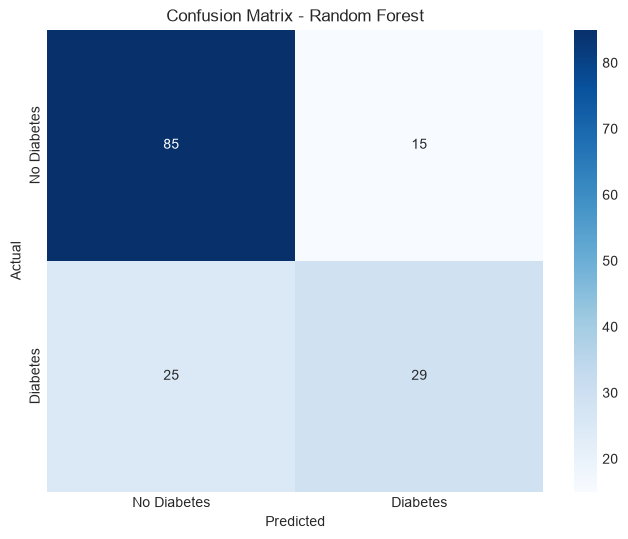

Confusion Matrix Interpretation:
True Negatives:  85 (Correctly predicted No Diabetes)
False Positives: 15 (Incorrectly predicted Diabetes)
False Negatives: 25 (Missed Diabetes cases)
True Positives:  29 (Correctly predicted Diabetes)


In [8]:
# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['No Diabetes', 'Diabetes'],
            yticklabels=['No Diabetes', 'Diabetes'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Random Forest')
plt.show()

print("Confusion Matrix Interpretation:")
print(f"True Negatives:  {cm[0,0]} (Correctly predicted No Diabetes)")
print(f"False Positives: {cm[0,1]} (Incorrectly predicted Diabetes)")
print(f"False Negatives: {cm[1,0]} (Missed Diabetes cases)")
print(f"True Positives:  {cm[1,1]} (Correctly predicted Diabetes)")

### 7.3 ROC Curve

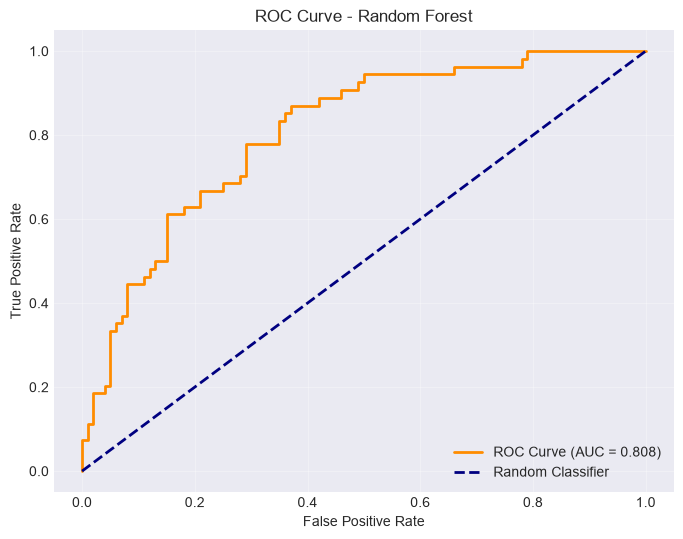

In [9]:
# ROC Curve
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)

fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(fpr, tpr, color='darkorange', linewidth=2, label=f'ROC Curve (AUC = {roc_auc:.3f})')
ax.plot([0, 1], [0, 1], color='navy', linestyle='--', linewidth=2, label='Random Classifier')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curve - Random Forest')
ax.legend(loc='lower right')
ax.grid(True, alpha=0.3)
plt.show()

## 8. Feature Importance

=== Feature Importance ===
                 Feature  Importance
                 Glucose    0.316495
                     BMI    0.176100
                     Age    0.113591
DiabetesPedigreeFunction    0.112421
                 Insulin    0.079405
             Pregnancies    0.071121
           BloodPressure    0.069533
           SkinThickness    0.061333



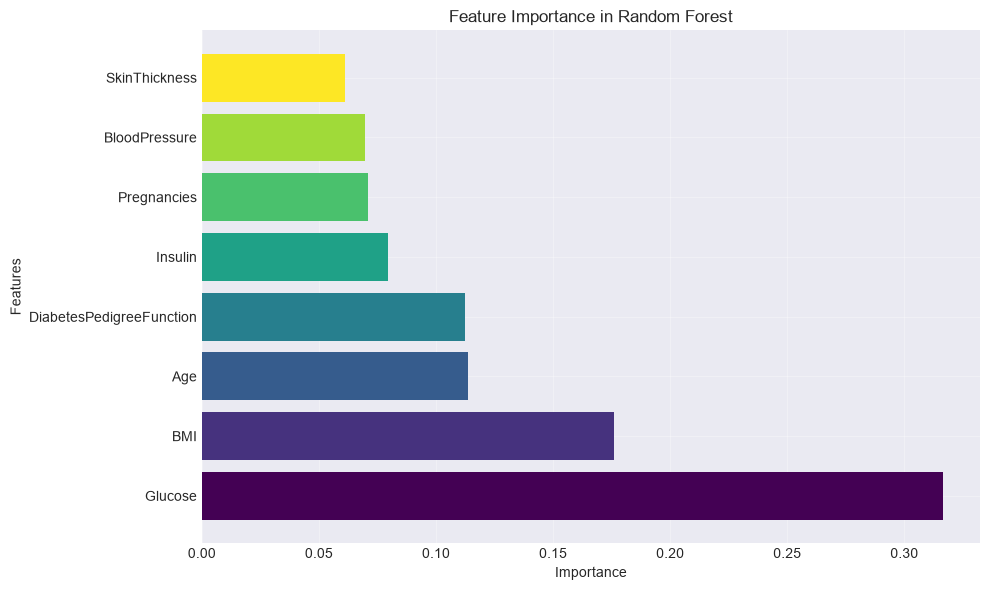

Top 5 Most Important Features:
1. Glucose: 0.3165
2. BMI: 0.1761
3. Age: 0.1136
4. DiabetesPedigreeFunction: 0.1124
5. Insulin: 0.0794


In [10]:
# Get feature importance
feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': rf_model.feature_importances_
}).sort_values('Importance', ascending=False)

print("=== Feature Importance ===")
print(feature_importance.to_string(index=False))
print()

# Visualize feature importance
fig, ax = plt.subplots(figsize=(10, 6))
colors = plt.cm.viridis(np.linspace(0, 1, len(feature_importance)))
ax.barh(feature_importance['Feature'], feature_importance['Importance'], color=colors)
ax.set_xlabel('Importance')
ax.set_ylabel('Features')
ax.set_title('Feature Importance in Random Forest')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Top features explanation
print("Top 5 Most Important Features:")
for i, (feature, importance) in enumerate(zip(feature_importance['Feature'][:5], 
                                              feature_importance['Importance'][:5]), 1):
    print(f"{i}. {feature}: {importance:.4f}")

## 10. Hyperparameter Tuning with Grid Search

In [11]:
# Search space for tuning
param_grid = {
    'n_estimators': [100, 200, 300, 500],
    'max_depth': [3, 5, 7, 9, None],
    'min_samples_split': [2, 5, 8, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2', None],
    'criterion': ['gini', 'entropy'],
    'class_weight': [None, 'balanced', 'balanced_subsample'],
    'bootstrap': [True]
}

print("=== Hyperparameter Tuning ===")
print(f"Search space size: {np.prod([len(v) for v in param_grid.values()])} combinations")
print("Running Randomized Search with class balancing and depth tuning...")

# Randomized search is more efficient here and captures the settings that matter most
rf_grid = RandomForestClassifier(random_state=42, oob_score=True, n_jobs=-1)
grid_search = RandomizedSearchCV(
    estimator=rf_grid,
    param_distributions=param_grid,
    n_iter=40,
    cv=5,
    scoring='accuracy',
    random_state=42,
    n_jobs=-1,
    verbose=1
)
grid_search.fit(X_train, y_train)

print("\n=== Best Parameters ===")
for param, value in grid_search.best_params_.items():
    print(f"{param}: {value}")

print(f"\nBest Cross-validation Score: {grid_search.best_score_:.4f}")
print(f"Test Set Score: {grid_search.score(X_test, y_test):.4f}")

=== Hyperparameter Tuning ===
Search space size: 4320 combinations
Running Randomized Search with class balancing and depth tuning...
Fitting 5 folds for each of 40 candidates, totalling 200 fits

=== Best Parameters ===
n_estimators: 200
min_samples_split: 5
min_samples_leaf: 4
max_features: log2
max_depth: 9
criterion: entropy
class_weight: balanced_subsample
bootstrap: True

Best Cross-validation Score: 0.7752
Test Set Score: 0.7403


In [12]:
# Train final model with best parameters
best_rf = grid_search.best_estimator_
y_pred_best = best_rf.predict(X_test)

# Compare with default model
default_acc = accuracy_score(y_test, y_pred)
tuned_acc = accuracy_score(y_test, y_pred_best)

print("=== Default vs Tuned Model ===")
print(f"Default Model Accuracy: {default_acc:.4f}")
print(f"Tuned Model Accuracy: {tuned_acc:.4f}")
print(f"Improvement: {(tuned_acc - default_acc)*100:.2f}%")
print()

print("Tuned Model Performance:")
print(classification_report(y_test, y_pred_best, target_names=['No Diabetes', 'Diabetes']))

=== Default vs Tuned Model ===
Default Model Accuracy: 0.7403
Tuned Model Accuracy: 0.7403
Improvement: 0.00%

Tuned Model Performance:
              precision    recall  f1-score   support

 No Diabetes       0.83      0.76      0.79       100
    Diabetes       0.61      0.70      0.66        54

    accuracy                           0.74       154
   macro avg       0.72      0.73      0.72       154
weighted avg       0.75      0.74      0.74       154



## 13. Visualization of Random Forest Structure

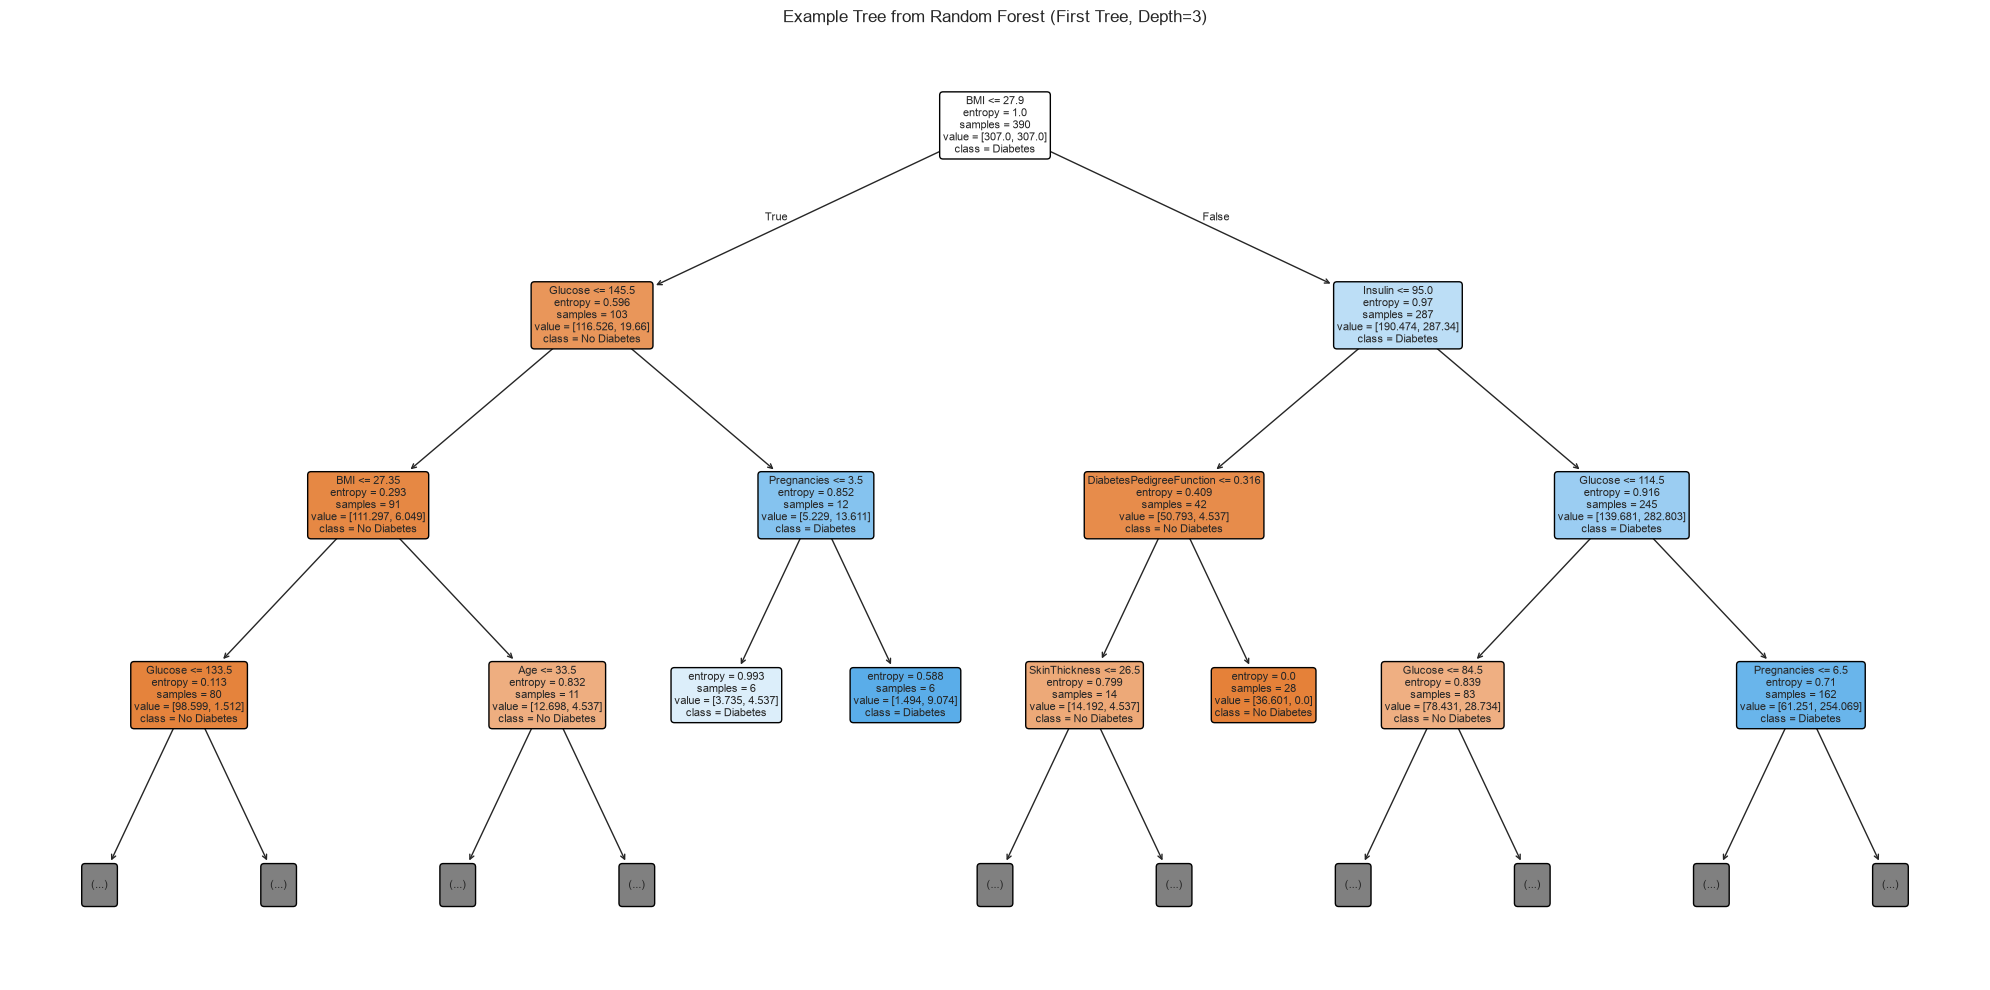

In [13]:
from sklearn.tree import plot_tree

# Visualize one tree from the forest
fig, ax = plt.subplots(figsize=(20, 10))
plot_tree(best_rf.estimators_[0], 
          feature_names=feature_names,
          class_names=['No Diabetes', 'Diabetes'],
          filled=True, 
          rounded=True,
          max_depth=3,
          fontsize=8)
plt.title('Example Tree from Random Forest (First Tree, Depth=3)')
plt.tight_layout()
plt.show()

## 15. Advantages and Disadvantages of Random Forest

### Advantages:

1. **High Accuracy**: Generally outperforms single decision trees
2. **Robust to Overfitting**: Ensemble averaging reduces overfitting
3. **Handles High Dimensional Data**: Works well with many features
4. **Feature Importance**: Built-in feature ranking
5. **Handles Missing Data**: Can handle missing values well
6. **Parallelizable**: Each tree can be built independently
7. **Non-linear Relationships**: Captures complex patterns
8. **Imbalanced Data**: Can handle class imbalance with class_weight

### Disadvantages:

1. **Less Interpretable**: Not as interpretable as single decision tree
2. **Memory Intensive**: Requires more memory for large forests
3. **Computationally Expensive**: Slower than simpler models
4. **Not Ideal for Online Learning**: Hard to update with new data
5. **Black Box**: Harder to explain predictions

### Best Practices:

1. **n_estimators**: Use more trees for better performance (100-500)
2. **max_features**: Use 'sqrt' for classification, 'log2' for regression
3. **max_depth**: Tune to prevent overfitting
4. **min_samples_split**: Start with 2, increase to reduce overfitting
5. **OOB Score**: Use for validation without cross-validation
6. **Feature Scaling**: Not required (tree-based models are scale-invariant)

## Final Notes

### When to Use Random Forest:

✅ **Use Random Forest when:**
- You need high accuracy
- Data has many features
- There are complex non-linear relationships
- You need feature importance scores
- Interpretability is not critical

❌ **Avoid Random Forest when:**
- Interpretability is crucial (use Decision Tree instead)
- Data is very small (< 100 samples)
- You need real-time predictions
- Memory is limited
- You need simple, linear relationships
